In [81]:
import cv2
import os
import numpy as np
import pandas as pd
import joblib
from tqdm import tqdm

In [82]:
# Step 1: Define Paths
data_folder = '/x1/ljiao/Bhanu/VIBE/cAvatar/data/'
output_folder = '/x1/ljiao/Bhanu/VIBE/cAvatar/output'
os.makedirs(output_folder, exist_ok=True)

In [83]:
# Step 2: Initialize Dataset List
dataset = []

In [84]:
# Step 3: Track Counts for Summary
# Initialize Counters
dataset = []
total_videos = 0
processed_videos = 0
skipped_videos = 0
mismatch_videos = 0

In [104]:
import os
import joblib

# Folder path
folder_path = "/x1/ljiao/Bhanu/VIBE/cAvatar/data"

# Function to check frame sequence and identify missing frames
def get_missing_frames(frame_ids):
    """Check if frame sequence is continuous and return missing frames."""
    sorted_frames = sorted(frame_ids)
    expected_sequence = list(range(sorted_frames[0], sorted_frames[-1] + 1))
    missing_frames = set(expected_sequence) - set(sorted_frames)
    return sorted(missing_frames)

# Iterate through all .pkl files
for file in os.listdir(folder_path):
    if file.endswith('.pkl'):
        file_path = os.path.join(folder_path, file)
        
        try:
            # Load .pkl file
            data = joblib.load(file_path)
            
            # Extract frame_ids (all person entries combined)
            frame_ids = set()
            for person_id in data:
                frame_ids.update(data[person_id].get('frame_ids', []))
            
            # Identify missing frames
            missing_frames = get_missing_frames(frame_ids)
            
            if missing_frames:
                print(f"❗ Missing frames detected in: {file}")
                print(f"   ➤ Missing frames: {missing_frames}")
            else:
                print(f"✅ Complete sequence in: {file}")
        
        except Exception as e:
            print(f"❌ Error reading {file}: {e}")


✅ Complete sequence in: G_I_DLE_G_I_DLE_Senorita_Lisa_Rhee_Dance_Coverkpop_dance_0_clip1.pkl
❗ Missing frames detected in: Little_of_the_Pre_STAR_battle_song_ji_let_dream_is_true_dance_4_clip1.pkl
   ➤ Missing frames: [11, 45, 46, 50, 52]
✅ Complete sequence in: Small_sprout_Sadistic_Love_come_back_after_half_a_year_s_the_original_version_dance_3_clip1.pkl
✅ Complete sequence in: Small_sprout_idiot_perfect_math_classroom_has_been_frozen_dance_2_clip1.pkl
❗ Missing frames detected in: G_I_DLE_Girls_LATATA_Latata_Dancer_Cover_Cover_by_HyeWon_Mirror_Mode_MAMA_ebIv5M6jqGIkpop_dance_17_clip1.pkl
   ➤ Missing frames: [26, 302, 303, 304, 306]
❗ Missing frames detected in: Small_sprout_brother_isn_t_at_home_sister_was_on_the_bed_himself_up_ones_of_dance_dance_4_clip1_clip1.pkl
   ➤ Missing frames: [102]
❗ Missing frames detected in: Small_sprout_Senorita_can_you_hug_me_again_portrait_Ver_dance_4_clip1.pkl
   ➤ Missing frames: [8, 9, 15, 30, 31, 32, 34, 35, 36, 39, 40, 41, 42, 43, 44, 45, 46, 4

In [ ]:
import os
import cv2
import joblib
import numpy as np
from tqdm import tqdm

# Initialize Counters
total_videos, processed_videos, skipped_videos, mismatch_videos = 0, 0, 0, 0
dataset = []
mismatched_videos = []  # Track mismatched videos

# Step 3: Process Each Video and Corresponding .pkl File
for file in tqdm(os.listdir(data_folder), desc="🔍 Processing Videos & .pkl Files"):
    if not file.endswith('.mp4') or file.endswith('_vibe_result.mp4'):
        continue

    total_videos += 1
    video_path = os.path.join(data_folder, file)
    pkl_path = os.path.join(data_folder, file.replace('.mp4', '.pkl'))

    # Check for Missing .pkl File
    if not os.path.exists(pkl_path):
        print(f"❗ Warning: No .pkl file found for {file}")
        skipped_videos += 1
        continue

    # Load .pkl File
    try:
        vibe_results = joblib.load(pkl_path)
    except Exception as e:
        print(f"❌ Error loading .pkl for {file}: {e}")
        skipped_videos += 1
        continue

    # Process Each Person in the .pkl File
    for person_id, data_1 in vibe_results.items():
        if not all(key in data_1 for key in ['pose', 'betas', 'pred_cam', 'joints3d', 'verts']):
            print(f"❗ Missing keys in {pkl_path}")
            skipped_videos += 1
            continue

        # Extract Data from .pkl File
        data_len = len(data_1['pose'])  # Exact number of frames required

        # Step 4: Check Frame Count in Video
        cap = cv2.VideoCapture(video_path)
        total_video_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        cap.release()

        # Skip Videos with Mismatch
        if total_video_frames != data_len:
            print(f"⚠️ Mismatch Found: {file} | 🎯 Expected in .pkl: {data_len} | 🟨 Video Frames: {total_video_frames}")
            mismatched_videos.append(file)
            continue  # Skip this video for now

        processed_videos += 1  # Only count successfully processed videos

        # Ensure valid camera data
        cam_repeated = (
            np.tile(data_1['pred_cam'], (data_len, 1)) 
            if len(data_1['pred_cam'].shape) == 1 
            else data_1['pred_cam']
        )

        # Step 5: Slice Video Frames and Create Dataset
        cap = cv2.VideoCapture(video_path)
        extracted_frames = 0

        for frame_idx in range(data_len):  # 🔥 Slice video strictly based on `.pkl` frame count
            ret, frame = cap.read()

            if not ret:
                print(f"❗ Incomplete Read at Frame {frame_idx} for {file}")
                break  # Stop if the video runs out of frames before reaching `data_len`

            image_path = os.path.join(output_folder, f"{file.replace('.mp4', '')}_frame_{frame_idx:04d}.jpg")

            # ✅ Sanity check: Ensure frame is successfully written
            if cv2.imwrite(image_path, frame):
                dataset.append({
                    'image_path': image_path,
                    'pose': data_1['pose'][frame_idx].tolist(),
                    'shape': data_1['betas'][frame_idx].tolist(),
                    'camera': cam_repeated[frame_idx].tolist(),
                    'joints': data_1['joints3d'][frame_idx].tolist(),
                    'vertices': data_1['verts'][frame_idx].tolist(),
                    'frame_ids': data_1.get('frame_ids', [0])[frame_idx],
                    'bboxes': data_1.get('bboxes', [[0, 0, 0, 0]])[frame_idx],
                    'joints2d': data_1.get('joints2d', np.zeros((300, 49, 2)))[frame_idx].tolist(),
                    'joints2d_img_coord': data_1.get('joints2d_img_coord', np.zeros((300, 49, 2)))[frame_idx].tolist()
                })
                extracted_frames += 1
            else:
                print(f"❗ Failed to save frame {frame_idx} for {file}")

        cap.release()

        # Frame Count Check (Logging Only for Debugging)
        print(f"✅ {file} - 🎯 Expected in .pkl: {data_len} | 🟩 Sliced: {extracted_frames}")

# Step 6: Final Summary
print("\n✅ Processing Complete!")
print(f"✅ Total Videos Processed Successfully: {processed_videos}/{total_videos} ({(processed_videos/total_videos)*100:.2f}%)")
print(f"❗ Total Skipped Videos (Errors/Missing .pkl): {skipped_videos}")
print(f"⚠️ Mismatched Videos (Skipped): {len(mismatched_videos)}")

# Step 7: Show Mismatched Videos
if mismatched_videos:
    print("\n🟠 List of Mismatched Videos:")
    for video in mismatched_videos:
        print(f" - {video}")


🔍 Processing Videos & .pkl Files:   0%|          | 1/466 [00:02<22:24,  2.89s/it]

✅ OO_west_4th_oO_Marine_Dreamin_dance_12_clip1.mp4 - 🎯 Expected in .pkl: 315 | 🟩 Sliced: 315
⚠️ Mismatch Found: G_I_DLE_G_I_DLE_Senorita_Dance_Cover_Ellen_and_Briankpop_dance_4_clip1.mp4 | 🎯 Expected in .pkl: 314 | 🟨 Video Frames: 317


🔍 Processing Videos & .pkl Files:   1%|          | 3/466 [00:03<07:56,  1.03s/it]

✅ G_I_DLE_G_I_DLE_Senorita_Dance_Cover_Ellen_and_Briankpop_dance_5_clip1.mp4 - 🎯 Expected in .pkl: 153 | 🟩 Sliced: 153
⚠️ Mismatch Found: Small_sprout_Senorita_can_you_hug_me_again_portrait_Ver_dance_4_clip1.mp4 | 🎯 Expected in .pkl: 128 | 🟨 Video Frames: 199


🔍 Processing Videos & .pkl Files:   1%|          | 5/466 [00:04<05:49,  1.32it/s]

✅ Little_Eva_heel_cheongsam_vertical_screen_dance_much_closer_to_your_cup_dance_2_clip1.mp4 - 🎯 Expected in .pkl: 105 | 🟩 Sliced: 105


🔍 Processing Videos & .pkl Files:   1%|▏         | 6/466 [00:04<04:42,  1.63it/s]

✅ FRIENDS_Girl_s_Generation_Girls_Generation_In_To_The_New_World_Into_The_New_World_Dance_Cover_DPOP_Friends_Y2TqV4nWEmQkpop_dance_8_clip3.mp4 - 🎯 Expected in .pkl: 100 | 🟩 Sliced: 100
⚠️ Mismatch Found: G_I_DLE_Girls_LATATA_Latata_Dancer_Cover_Cover_by_HyeWon_Mirror_Mode_MAMA_ebIv5M6jqGIkpop_dance_5_clip1.mp4 | 🎯 Expected in .pkl: 310 | 🟨 Video Frames: 317


🔍 Processing Videos & .pkl Files:   2%|▏         | 8/466 [00:05<03:50,  1.98it/s]

✅ FRIENDS_PRISTIN_PRISTIN_Get_It_As_You_Like_It_Dance_Cover_DPOP_Friends_Mirror_Mode_7S8cmJ32JNckpop_dance_15_clip1.mp4 - 🎯 Expected in .pkl: 320 | 🟩 Sliced: 320


In [96]:
import os
import joblib
from tqdm import tqdm

data_folder = '/x1/ljiao/Bhanu/VIBE/cAvatar/data/'
total_frames = 0

# Step 1: Iterate through all .pkl files
for file in tqdm(os.listdir(data_folder), desc="🔍 Counting Frames in .pkl Files"):
    if file.endswith('.pkl'):
        base_name = file.replace('.pkl', '.mp4')  # Match `.pkl` name with `.mp4`

        # Skip mismatched videos
        if base_name in mismatched_videos:
            continue  

        pkl_path = os.path.join(data_folder, file)

        # Step 2: Load .pkl File and Sum the Frames
        try:
            vibe_results = joblib.load(pkl_path)
            for person_id, data_1 in vibe_results.items():
                total_frames += len(data_1['pose'])  # Each entry in 'pose' corresponds to one frame
        except Exception as e:
            print(f"❗ Error loading {file}: {e}")

# Step 3: Display Total Frames
print(f"\n✅ Total Frames Across All .pkl Files (Excluding Mismatched Videos): {total_frames}")


🔍 Counting Frames in .pkl Files: 100%|██████████| 1275/1275 [00:01<00:00, 820.98it/s]


✅ Total Frames Across All .pkl Files (Excluding Mismatched Videos): 76340


In [34]:
import cv2
import os
from tqdm import tqdm

data_folder = "/x1/ljiao/Bhanu/VIBE/cAvatar/data/"
corrupted_videos = []

for file in tqdm(os.listdir(data_folder), desc="🔍 Checking Videos"):
    if file.endswith('.mp4') and '_vibe_result.mp4' not in file:
        video_path = os.path.join(data_folder, file)
        
        cap = cv2.VideoCapture(video_path)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        corrupted = False
        for _ in range(total_frames):
            ret, frame = cap.read()
            if not ret:
                corrupted = True
                break

        cap.release()

        if corrupted:
            print(f"❗ Corrupted video detected: {file}")
            corrupted_videos.append(file)

print(f"\n✅ Total Corrupted Videos: {len(corrupted_videos)}")
if corrupted_videos:
    print("🟠 List of Corrupted Videos:")
    for video in corrupted_videos:
        print(video)


🔍 Checking Videos: 100%|██████████| 1290/1290 [01:29<00:00, 14.34it/s]


✅ Total Corrupted Videos: 0


In [35]:
import os
import joblib
from tqdm import tqdm

data_folder = '/x1/ljiao/Bhanu/VIBE/cAvatar/data/'
corrupted_pkl_files = []

# Step 1: Iterate through all .pkl files
for file in tqdm(os.listdir(data_folder), desc="🔍 Checking .pkl Files"):
    if file.endswith('.pkl'):
        pkl_path = os.path.join(data_folder, file)

        # Step 2: Attempt to Load Each .pkl File
        try:
            _ = joblib.load(pkl_path)
        except Exception as e:
            print(f"❗ Corrupted .pkl file: {file} | Error: {e}")
            corrupted_pkl_files.append(file)

# Step 3: Summary
if corrupted_pkl_files:
    print(f"\n❗ Total Corrupted .pkl Files: {len(corrupted_pkl_files)}")
    print("🔎 List of Corrupted .pkl Files:")
    for corrupted_file in corrupted_pkl_files:
        print(f"  - {corrupted_file}")
else:
    print("\n✅ No corrupted .pkl files found!")


🔍 Checking .pkl Files: 100%|██████████| 1290/1290 [00:03<00:00, 343.60it/s]


✅ No corrupted .pkl files found!


In [94]:
import os
import joblib
from tqdm import tqdm

data_folder = '/x1/ljiao/Bhanu/VIBE/cAvatar/data/'
total_frames = 0

# Step 1: Iterate through all .pkl files
for file in tqdm(os.listdir(data_folder), desc="🔍 Counting Frames in .pkl Files"):
    if file.endswith('.pkl'):
        pkl_path = os.path.join(data_folder, file)

        # Step 2: Load .pkl File and Sum the Frames
        try:
            vibe_results = joblib.load(pkl_path)
            for person_id, data_1 in vibe_results.items():
                total_frames += len(data_1['pose'])  # Each entry in 'pose' corresponds to one frame
        except Exception as e:
            print(f"❗ Error loading {file}: {e}")

# Step 3: Display Total Frames
print(f"\n✅ Total Frames Across All .pkl Files: {total_frames}")




🔍 Counting Frames in .pkl Files: 100%|██████████| 1275/1275 [00:02<00:00, 599.42it/s]


✅ Total Frames Across All .pkl Files: 105361


In [90]:
import os
import joblib
from tqdm import tqdm

data_folder = '/x1/ljiao/Bhanu/VIBE/cAvatar/data/'
output_folder = '/x1/ljiao/Bhanu/VIBE/cAvatar/output/'

# Track issues
mismatch_videos = []

for file in tqdm(os.listdir(data_folder), desc="🔍 Checking Mismatches"):
    if file.endswith('.pkl'):
        pkl_path = os.path.join(data_folder, file)
        expected_frames = 0

        try:
            vibe_results = joblib.load(pkl_path)
            for person_id, data_1 in vibe_results.items():
                expected_frames = len(data_1['pose'])
        except Exception as e:
            continue

        # Count sliced frames
        video_name = file.replace('.pkl', '')
        sliced_frames = len([f for f in os.listdir(output_folder) if f.startswith(video_name)])

        if expected_frames != sliced_frames:
            mismatch_videos.append(f"{video_name}: Expected {expected_frames}, Found {sliced_frames}")

# Display Results
if mismatch_videos:
    print("\n⚠️ Mismatched Videos Found:")
    for video in mismatch_videos:
        print(f"❗ {video}")
else:
    print("\n✅ All videos are correctly sliced.")


🔍 Checking Mismatches: 100%|██████████| 1275/1275 [00:40<00:00, 31.64it/s]


⚠️ Mismatched Videos Found:
❗ Small_short_skirt_of_rabbit_ears_COS_sister_curtilage_dance_3_jumpers_dance_26_clip1: Expected 190, Found 282
❗ O_Ziqi_double_jump_APINK_pink_ones_brainwashing_imitate_new_song_dance_dance_4_clip1: Expected 244, Found 333
❗ Small_primary_touch_the_sky_here_is_I_m_looking_forward_to_the_future_of_the_double_horsetail_girl_feet_or_small_lolita_dresses_dance_15_clip1: Expected 154, Found 326
❗ Ziqi_double_jump_TWICE_Breakthrough_speed_grilled_new_P2_vertical_screen_version_of_P2_TWICE_Breakthrough_Ziqi_vertical_screen_version_dance_6_clip1: Expected 77, Found 204
❗ Small_primary_touch_the_sky_here_is_I_m_looking_forward_to_the_future_of_the_double_horsetail_girl_feet_or_small_lolita_dresses_dance_0_clip1: Expected 49, Found 112
❗ FRIENDS_LOVELYZ_Lovelyz_AH_CHOO_Ah_Chu_Dance_Cover_DPOP_Friends_ZPzlZ9tM3bYkpop_dance_14_clip1: Expected 25, Found 299


In [78]:
import os
import re

# Define paths
input_folder = '/x1/ljiao/Bhanu/VIBE/cAvatar/data'
output_folder = '/x1/ljiao/Bhanu/VIBE/cAvatar/output'

# Step 1: Collect unique base names from `/input` (excluding `_vibe_result.mp4`)
input_videos = set(
    os.path.splitext(file)[0]
    for file in os.listdir(input_folder)
    if file.endswith('.mp4') and not file.endswith('_vibe_result.mp4')
)

# Step 2: Collect unique base names from `/output` correctly
output_videos = set(
    re.sub(r'_frame_\d{4}', '', file).replace('.jpg', '')
    for file in os.listdir(output_folder)
    if file.endswith('.jpg')
)

# Step 3: Cross-check by stripping folder paths for accuracy
input_videos_cleaned = set(os.path.basename(video) for video in input_videos)
output_videos_cleaned = set(os.path.basename(video) for video in output_videos)

# Step 4: Find missing videos
missing_videos = input_videos_cleaned - output_videos_cleaned

# Display Results
print(f"✅ Total Input Videos: {len(input_videos_cleaned)}")
print(f"✅ Total Processed Videos: {len(output_videos_cleaned)}")
print(f"❗ Missing Videos: {len(missing_videos)}")

if missing_videos:
    print("\n🟠 List of Missing Videos:")
    for video in sorted(missing_videos):
        print(video)
else:
    print("\n✅ No missing videos detected!")


✅ Total Input Videos: 425
✅ Total Processed Videos: 425
❗ Missing Videos: 0

✅ No missing videos detected!


In [58]:
import joblib
import os

pkl_files = [
    'Little_of_Siren_for_birthday_wish_all_Pisces_born_sexy_fish_fish_dance_online_edition_MV_dance_1_clip1.pkl',
    'Little_of_Siren_for_birthday_wish_all_Pisces_born_sexy_fish_fish_dance_online_edition_MV_dance_1_clip2.pkl',
    'Little_of_the_Pre_STAR_battle_song_ji_let_dream_is_true_dance_5_clip2.pkl',
    'Small_sprout_SnowHalation_merry_Christmas_if_miracle_has_color_dance_9_clip1.pkl',
    'Small_sprout_Violeta_indistinctly_in_the_MV_version_of_a_key_change__change_version_dance_3_clip4.pkl'
]

data_folder = "/x1/ljiao/Bhanu/VIBE/cAvatar/data"

for pkl_file in pkl_files:
    pkl_path = os.path.join(data_folder, pkl_file)
    if os.path.exists(pkl_path):
        vibe_data = joblib.load(pkl_path)
        for person_id, data in vibe_data.items():
            print(f"✅ {pkl_file} | Person ID: {person_id} | Frame Count: {len(data['pose'])}")
    else:
        print(f"❗ {pkl_file} not found.")



In [59]:
import joblib
import os

pkl_files = [
    'Little_of_Siren_for_birthday_wish_all_Pisces_born_sexy_fish_fish_dance_online_edition_MV_dance_1_clip1.pkl',
    'Little_of_Siren_for_birthday_wish_all_Pisces_born_sexy_fish_fish_dance_online_edition_MV_dance_1_clip2.pkl',
    'Little_of_the_Pre_STAR_battle_song_ji_let_dream_is_true_dance_5_clip2.pkl',
    'Small_sprout_SnowHalation_merry_Christmas_if_miracle_has_color_dance_9_clip1.pkl',
    'Small_sprout_Violeta_indistinctly_in_the_MV_version_of_a_key_change__change_version_dance_3_clip4.pkl'
]

data_folder = "/x1/ljiao/Bhanu/VIBE/cAvatar/data"

for pkl_file in pkl_files:
    pkl_path = os.path.join(data_folder, pkl_file)
    if os.path.exists(pkl_path):
        vibe_data = joblib.load(pkl_path)
        for person_id, data in vibe_data.items():
            print(f"✅ {pkl_file} | Person ID: {person_id} | Frame Count: {len(data['pose'])}")
    else:
        print(f"❗ {pkl_file} not found.")


In [60]:
import joblib
import numpy as np

# Path to your .pkl file
pkl_path = '/x1/ljiao/Bhanu/VIBE/cAvatar/data/Little_of_Siren_for_birthday_wish_all_Pisces_born_sexy_fish_fish_dance_online_edition_MV_dance_1_clip1.pkl'

# Load .pkl file
try:
    data = joblib.load(pkl_path)
    print(f"✅ Successfully loaded: {pkl_path}")
except Exception as e:
    print(f"❌ Error loading .pkl file: {e}")
    exit()

# Inspect top-level structure
print(f"\n🔍 Top-level keys in the .pkl file: {list(data.keys())}")

# Inspect contents of each key
for person_id, person_data in data.items():
    print(f"\n🟩 Person ID: {person_id}")
    
    for key, value in person_data.items():
        if isinstance(value, np.ndarray):
            print(f"  ✅ Key: '{key}' | Shape: {value.shape} | Type: {value.dtype}")
            print(f"     First 2 Entries: {value[:2]}")
        elif isinstance(value, list):
            print(f"  ✅ Key: '{key}' | List Length: {len(value)}")
            print(f"     First 2 Entries: {value[:2]}")
        else:
            print(f"  ✅ Key: '{key}' | Type: {type(value)}")
            print(f"     Value: {value}")


✅ Successfully loaded: /x1/ljiao/Bhanu/VIBE/cAvatar/data/Little_of_Siren_for_birthday_wish_all_Pisces_born_sexy_fish_fish_dance_online_edition_MV_dance_1_clip1.pkl

🔍 Top-level keys in the .pkl file: []


In [74]:
import joblib

file = '/x1/ljiao/Bhanu/VIBE/cAvatar/data/Little_of_the_Pre_STAR_battle_song_ji_let_dream_is_true_dance_5_clip2.pkl'
data = joblib.load(file)

if not data:
    print("❗ This .pkl file is empty (no detected data).")
else:
    for person_id, person_data in data.items():
        print(f"✅ Person ID {person_id} - Pose Length: {len(person_data.get('pose', []))}")


❗ This .pkl file is empty (no detected data).


In [105]:
import os
import joblib
import numpy as np
from tqdm import tqdm

# Step 1: Define Paths
data_folder = '/x1/ljiao/Bhanu/VIBE/cAvatar/data/'

# Step 2: Track Missing Data
missing_joints2d = []

# Step 3: Process Each .pkl File
for file in tqdm(os.listdir(data_folder), desc="🔍 Checking .pkl Files"):
    if file.endswith('.pkl'):
        pkl_path = os.path.join(data_folder, file)
        
        try:
            vibe_results = joblib.load(pkl_path)
        except Exception as e:
            print(f"❌ Error loading .pkl for {file}: {e}")
            continue

        # Step 4: Check for Missing `joints2d`
        for person_id, data_1 in vibe_results.items():
            if 'joints2d' not in data_1 or data_1['joints2d'] is None:
                missing_joints2d.append(file)
                break  # No need to check other persons in the same file

# Step 5: Display Results
if missing_joints2d:
    print(f"\n❗ {len(missing_joints2d)} files are missing `joints2d` data:")
    for file in missing_joints2d:
        print(f" - {file}")
else:
    print("\n✅ All `.pkl` files contain `joints2d` data.")


🔍 Checking .pkl Files: 100%|██████████| 729/729 [00:01<00:00, 566.55it/s]


✅ All `.pkl` files contain `joints2d` data.


In [21]:
import pandas as pd
import numpy as np
import os
from tqdm import tqdm  # For visual progress tracking

# Step 1: Ensure Correct Data Types Before CSV Conversion
def ensure_valid_data_type(entry):
    keys_to_check = ['pose', 'shape', 'camera', 'joints', 'vertices', 
                     'frame_ids', 'bboxes', 'joints2d', 'joints2d_img_coord']

    for key in keys_to_check:
        value = entry.get(key, None)
        
        # Ensure valid array format (handles lists, np arrays, etc.)
        if isinstance(value, (list, np.ndarray)):
            entry[key] = np.array(value).tolist()  # Convert array-like data to list for CSV compatibility
        else:
            entry[key] = np.zeros((0,)).tolist()  # Fallback to empty array for missing values

# Step 2: Apply Data Type Correction to All Entries
print(f"🔄 Processing {len(dataset)} records...")

for idx, entry in tqdm(enumerate(dataset), total=len(dataset), desc="🔍 Converting Data", unit="record"):
    ensure_valid_data_type(entry)
    
    # Show progress every 10% for better tracking
    if idx % (len(dataset) // 10) == 0:
        print(f"✅ Processed {idx}/{len(dataset)} records ({(idx/len(dataset))*100:.2f}%)")

# Step 3: Create DataFrame and Save as CSV
dataset_df = pd.DataFrame(dataset)

# Step 4: Fill Missing Values with Default Values
dataset_df.fillna("N/A", inplace=True)

# Step 5: Save as CSV
dataset_csv_path = os.path.join(output_folder, 'dataset.csv')
dataset_df.to_csv(dataset_csv_path, index=False)

print(f"✅ Dataset created successfully at: {dataset_csv_path}")
print(f"✅ Total Records Processed: {len(dataset)}")


🔄 Processing 152055 records...


🔍 Converting Data:   0%|          | 26/152055 [00:00<09:59, 253.42record/s]

✅ Processed 0/152055 records (0.00%)


🔍 Converting Data:  10%|█         | 15248/152055 [01:37<05:49, 391.02record/s]  

✅ Processed 15205/152055 records (10.00%)


...

✅ Processed 76025/152055 records (50.00%)


🔍 Converting Data:  60%|██████    | 91292/152055 [06:06<02:37, 386.43record/s]

✅ Processed 91230/152055 records (60.00%)


🔍 Converting Data:  67%|██████▋   | 101793/152055 [08:06<04:00, 209.13record/s]


KeyboardInterrupt: 

In [23]:
print(f"✅ Total records in dataset: {len(dataset)}")
unique_image_paths = set(entry['image_path'] for entry in dataset)
print(f"✅ Unique image entries: {len(unique_image_paths)}")


✅ Total records in dataset: 152055
✅ Unique image entries: 105336


In [103]:
# Step 3: Check for `None` values and display shapes
none_keys_summary = {}
all_valid = True  # Flag to track if everything is valid

for person_id, data_1 in tqdm(vibe_results.items(), desc="🔍 Checking data"):
    none_keys = []

    # Detailed print for each key
    for key in data_1.keys():
        if data_1[key] is None:
            none_keys.append(key)
        else:
            data_shape = np.array(data_1[key]).shape
            print(f"✅ Key '{key}' has valid data. Shape: {data_shape}")

    # Track missing keys
    if none_keys:
        none_keys_summary[person_id] = none_keys
        print(f"❗ Person ID {person_id} missing keys: {none_keys}")
        all_valid = False
    else:
        print(f"✅ All keys contain valid data for Person ID {person_id}.")

# Step 4: Summary
if all_valid:
    print("\n✅ No `None` values found in the .pkl file. All data is complete!")
elif none_keys_summary:
    print(f"\n❗ Summary of missing keys: {none_keys_summary}")



🔍 Checking data: 100%|██████████| 1/1 [00:00<00:00, 383.78it/s]

✅ Key 'pred_cam' has valid data. Shape: (300, 3)
✅ Key 'orig_cam' has valid data. Shape: (300, 4)
✅ Key 'verts' has valid data. Shape: (300, 6890, 3)
✅ Key 'pose' has valid data. Shape: (300, 72)
✅ Key 'betas' has valid data. Shape: (300, 10)
✅ Key 'joints3d' has valid data. Shape: (300, 49, 3)
✅ Key 'joints2d' has valid data. Shape: (300, 49, 2)
✅ Key 'joints2d_img_coord' has valid data. Shape: (300, 49, 2)
✅ Key 'bboxes' has valid data. Shape: (300, 4)
✅ Key 'frame_ids' has valid data. Shape: (300,)
✅ All keys contain valid data for Person ID 1.

✅ No `None` values found in the .pkl file. All data is complete!


In [107]:
import joblib
import pickle
import numpy as np

# Load .pkl file
vibe_results = joblib.load(pkl_path)

# Extract required data
if 1 in vibe_results:
    data_1 = vibe_results[1]  # Extract key '1' data

    # Correct Mapping for cAvatar with ALL important parameters
    converted_data = {
        'pose': np.array(data_1['pose']),         # Mapped from 'pose'
        'shape': np.array(data_1['betas']),       # Mapped from 'betas'
        'camera': np.array(data_1['pred_cam']),   # Mapped from 'pred_cam'
        'joints': np.array(data_1['joints3d']),   # Mapped from 'joints3d'
        'vertices': np.array(data_1['verts']),    # Mapped from 'verts'
        'joints2d': np.array(data_1.get('joints2d', np.zeros((300, 49, 2)))),  
        'joints2d_img_coord': np.array(data_1.get('joints2d_img_coord', np.zeros((300, 49, 2)))),
        'bboxes': np.array(data_1.get('bboxes', np.zeros((300, 4)))),  
        'frame_ids': np.array(data_1.get('frame_ids', np.arange(300)))  
    }

    # Save as new .pkl file for cAvatar
    new_pkl_path = "/x1/ljiao/Bhanu/VIBE/output/converted_vibe_output.pkl"
    with open(new_pkl_path, 'wb') as f:
        pickle.dump(converted_data, f)

    print(f"✅ Converted .pkl file saved at: {new_pkl_path}")
else:
    print("❌ Key 1 not found.")


✅ Converted .pkl file saved at: /x1/ljiao/Bhanu/VIBE/output/converted_vibe_output.pkl


In [110]:
# Step 2: Function to Slice Video
def slice_video(video_path, frame_indices, output_dir):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Ensure number of frames in video matches expected frame indices
    if len(frame_indices) > total_frames:
        raise ValueError(f"Error: Video has {total_frames} frames, but .pkl file expects {len(frame_indices)} frames.")

    frame_count = 0
    saved_frames = 0

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        if saved_frames < len(frame_indices) and frame_count == frame_indices[saved_frames]:
            output_path = os.path.join(output_dir, f"frame_{frame_count:04d}.jpg")
            cv2.imwrite(output_path, frame)
            saved_frames += 1
        
        frame_count += 1

    cap.release()
    print(f"Video '{video_path}' sliced successfully with {saved_frames} frames.")



In [71]:
# Slice the video accordingly
video_output_dir = os.path.join(output_folder, 'sliced_video')
os.makedirs(video_output_dir, exist_ok=True)

slice_video(video_path, frame_indices, video_output_dir)

Video '/x1/ljiao/Bhanu/VIBE/sample_video.mp4' sliced successfully with 300 frames.


In [112]:
# Build dataset reference with all key data points
dataset = []

# Use 'data_1' to align with the updated structure
data_1 = vibe_results[1]  # Extract key '1' data

data_len = min(len(data_1['pose']), len(frame_indices))

# Handle 'camera' correctly
if 'pred_cam' in data_1 and data_1['pred_cam'] is not None:
    if len(data_1['pred_cam'].shape) == 1:  
        cam_repeated = np.tile(data_1['pred_cam'], (data_len, 1))  # Repeat for all frames
    else:
        cam_repeated = data_1['pred_cam']
else:
    cam_repeated = np.zeros((data_len, 3))  # Safe fallback for camera data

# Dataset Creation Loop
for idx in range(data_len):
    frame_index = frame_indices[idx]

    dataset.append({
        'image_path': f"{video_output_dir}/frame_{frame_index:04d}.jpg",
        'pose': data_1.get('pose', np.zeros((data_len, 72)))[idx].tolist(),  
        'shape': data_1.get('betas', np.zeros((data_len, 10)))[idx].tolist(),  
        'camera': cam_repeated[idx].tolist(),   
        'joints': data_1.get('joints3d', [[0.0, 0.0, 0.0]] * 49)[idx].tolist(),
        'vertices': data_1.get('verts', [[0.0, 0.0, 0.0]] * 6890)[idx].tolist(),
        'frame_ids': data_1.get('frame_ids', [0])[idx],
        'bboxes': data_1.get('bboxes', [[0, 0, 0, 0]])[idx],
        'joints2d': data_1.get('joints2d', np.zeros((data_len, 49, 2)))[idx].tolist(),
        'joints2d_img_coord': data_1.get('joints2d_img_coord', np.zeros((data_len, 49, 2)))[idx].tolist()
    })

print(f"✅ Dataset successfully created with {len(dataset)} entries.")


✅ Dataset successfully created with 300 entries.


In [114]:
import pandas as pd
import numpy as np
import os

# Step 1: Ensure Correct Data Types Before CSV Conversion
def ensure_valid_data_type(entry):
    # Convert each key's data to a proper type if needed
    for key in ['pose', 'shape', 'camera', 'joints', 'vertices', 
                'frame_ids', 'bboxes', 'joints2d', 'joints2d_img_coord']:
        
        value = entry.get(key, None)
        
        # Ensure valid array format (handles lists, np arrays, etc.)
        if isinstance(value, (list, np.ndarray)):
            entry[key] = value  # Keep as proper numerical data type
        else:
            entry[key] = np.array(value) if value is not None else np.zeros((0,))  # Fallback to empty array

# Step 2: Apply Data Type Correction to All Entries
for entry in dataset:
    ensure_valid_data_type(entry)

# Step 3: Create DataFrame and Save as CSV
dataset_df = pd.DataFrame(dataset)

# Step 4: Fill Missing Values with Default Values
dataset_df.fillna("N/A", inplace=True)

# Step 5: Save as CSV
dataset_csv_path = os.path.join(output_folder, 'dataset.csv')
dataset_df.to_csv(dataset_csv_path, index=False)

print(f"✅ Dataset created successfully at: {dataset_csv_path}")



✅ Dataset created successfully at: /x1/ljiao/Bhanu/VIBE/output_dataset/dataset.csv


In [115]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Step 1: Load Dataset
dataset_csv_path = os.path.join(output_folder, 'dataset.csv')
dataset_df = pd.read_csv(dataset_csv_path)

# Step 2: Extract Input (X) and Target (Y)
X = dataset_df[['image_path']].values.flatten()   # Input: Image paths
Y = dataset_df[['pose', 'shape', 'camera', 'joints', 'vertices']].values  # Output: Mesh data

# Step 3: Split Data into Train/Val/Test Sets (80/10/10 Split)
X_train, X_temp, Y_train, Y_temp = train_test_split(X, Y, test_size=0.2, random_state=42)
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.5, random_state=42)

# Step 4: Save Data in .npy Format for Faster Loading
np.save(os.path.join(output_folder, 'X_train.npy'), X_train)
np.save(os.path.join(output_folder, 'Y_train.npy'), Y_train)
np.save(os.path.join(output_folder, 'X_val.npy'), X_val)
np.save(os.path.join(output_folder, 'Y_val.npy'), Y_val)
np.save(os.path.join(output_folder, 'X_test.npy'), X_test)
np.save(os.path.join(output_folder, 'Y_test.npy'), Y_test)

print(f"✅ Data successfully split and saved in {output_folder}")
print(f"🟩 Train Samples: {len(X_train)} | 🟦 Val Samples: {len(X_val)} | 🟥 Test Samples: {len(X_test)}")


✅ Data successfully split and saved in /x1/ljiao/Bhanu/VIBE/output_dataset/
🟩 Train Samples: 240 | 🟦 Val Samples: 30 | 🟥 Test Samples: 30


In [118]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np
from PIL import Image
import os

# Step 1: Custom Dataset Class for Data Loading
class HumanMeshDataset(Dataset):
    def __init__(self, X_paths, Y_data, transform=None):
        self.X_paths = X_paths
        self.Y_data = Y_data
        self.transform = transform

    def __len__(self):
        return len(self.X_paths)

    def __getitem__(self, idx):
        img_path = self.X_paths[idx]
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        target = torch.tensor(self.Y_data[idx], dtype=torch.float32)  # Now guaranteed float32
        return image, target

# Step 2: Data Preparation
def load_data(output_folder):
    X_train = np.load(os.path.join(output_folder, 'X_train.npy'), allow_pickle=True)
    Y_train = np.load(os.path.join(output_folder, 'Y_train.npy'), allow_pickle=True)
    X_val = np.load(os.path.join(output_folder, 'X_val.npy'), allow_pickle=True)
    Y_val = np.load(os.path.join(output_folder, 'Y_val.npy'), allow_pickle=True)

    # Clean Data — Ensure all targets are proper float32 tensors
    def clean_target_data(target_data):
        cleaned_data = []
        for entry in target_data:
            if isinstance(entry, np.ndarray) and entry.shape == (6890, 3):
                cleaned_data.append(entry.astype(np.float32))
            else:
                cleaned_data.append(np.zeros((6890, 3), dtype=np.float32))  # Safe fallback
        return np.array(cleaned_data)

    # Clean and prepare Y data
    Y_train = clean_target_data(Y_train)
    Y_val = clean_target_data(Y_val)

    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    train_dataset = HumanMeshDataset(X_train, Y_train, transform=transform)
    val_dataset = HumanMeshDataset(X_val, Y_val, transform=transform)

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

    return train_loader, val_loader

# Step 3: Model Architecture (ResNet + cAvatar Inspired)
class HumanMeshPredictor(nn.Module):
    def __init__(self, output_dim=6890*3):  # 6890 vertices × 3D coordinates
        super(HumanMeshPredictor, self).__init__()

        # ResNet Backbone (Encoder) - Updated to use latest 'weights' syntax
        resnet = models.resnet50(weights='IMAGENET1K_V1')
        self.encoder = nn.Sequential(*list(resnet.children())[:-1])  # Remove FC layer

        # Fully Connected Layer for Prediction
        self.fc = nn.Linear(2048, output_dim)  # 2048 (ResNet output features)

    def forward(self, x):
        features = self.encoder(x)
        features = features.view(features.size(0), -1)  # Flatten
        mesh_output = self.fc(features)
        return mesh_output.view(-1, 6890, 3)  # Reshape back to 3D coordinates

# Step 4: Training Function
def train(model, train_loader, val_loader, num_epochs=25, learning_rate=0.0001):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)

    loss_fn = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    best_val_loss = float('inf')
    checkpoint_path = './human_mesh_model.pth'

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0

        for images, targets in train_loader:
            images, targets = images.to(device), targets.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, targets)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        avg_train_loss = train_loss / len(train_loader)

        # Validation Step
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, targets in val_loader:
                images, targets = images.to(device), targets.to(device)
                outputs = model(images)
                loss = loss_fn(outputs, targets)
                val_loss += loss.item()

        avg_val_loss = val_loss / len(val_loader)

        print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

        # Save model checkpoint if validation loss improves
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), checkpoint_path)
            print(f"✅ Model checkpoint saved at {checkpoint_path}")

    print("✅ Training complete!")

# Step 5: Evaluation Function
def evaluate(model, val_loader):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    model.eval()

    total_loss = 0.0
    loss_fn = nn.MSELoss()

    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(device), targets.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, targets)
            total_loss += loss.item()

    avg_loss = total_loss / len(val_loader)
    print(f"🟩 Final Validation Loss: {avg_loss:.4f}")

# Step 6: Main Execution
if __name__ == "__main__":
    # Load Data
    output_folder = '/x1/ljiao/Bhanu/VIBE/output_dataset/'
    train_loader, val_loader = load_data(output_folder)

    # Initialize and Train Model
    model = HumanMeshPredictor()
    train(model, train_loader, val_loader, num_epochs=25, learning_rate=0.0001)

    # Evaluate Model
    evaluate(model, val_loader)



Epoch [1/25] | Train Loss: 0.0266 | Val Loss: 0.0234
✅ Model checkpoint saved at ./human_mesh_model.pth
Epoch [2/25] | Train Loss: 0.0051 | Val Loss: 0.0250
Epoch [3/25] | Train Loss: 0.0019 | Val Loss: 0.0075
✅ Model checkpoint saved at ./human_mesh_model.pth
Epoch [4/25] | Train Loss: 0.0008 | Val Loss: 0.0022
✅ Model checkpoint saved at ./human_mesh_model.pth
Epoch [5/25] | Train Loss: 0.0003 | Val Loss: 0.0007
✅ Model checkpoint saved at ./human_mesh_model.pth
Epoch [6/25] | Train Loss: 0.0002 | Val Loss: 0.0003
✅ Model checkpoint saved at ./human_mesh_model.pth
Epoch [7/25] | Train Loss: 0.0001 | Val Loss: 0.0001
✅ Model checkpoint saved at ./human_mesh_model.pth
Epoch [8/25] | Train Loss: 0.0001 | Val Loss: 0.0001
✅ Model checkpoint saved at ./human_mesh_model.pth
Epoch [9/25] | Train Loss: 0.0000 | Val Loss: 0.0000
✅ Model checkpoint saved at ./human_mesh_model.pth
Epoch [10/25] | Train Loss: 0.0000 | Val Loss: 0.0000
✅ Model checkpoint saved at ./human_mesh_model.pth
Epoch [11/

In [119]:
import torch
from torchvision import transforms
from PIL import Image
import numpy as np

# Load Model
model = HumanMeshPredictor()  # Same model class used during training
model.load_state_dict(torch.load('./human_mesh_model.pth'))
model.eval()

# Move to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)


HumanMeshPredictor(
  (encoder): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
          (0): 

In [120]:
# Load Test Data
output_folder = '/x1/ljiao/Bhanu/VIBE/output_dataset/'
X_test = np.load(os.path.join(output_folder, 'X_test.npy'), allow_pickle=True)
Y_test = np.load(os.path.join(output_folder, 'Y_test.npy'), allow_pickle=True)

# Image Transformation (Same as Training)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


In [121]:
# Prediction Function
def predict_image(model, image_path):
    image = Image.open(image_path).convert('RGB')
    image = transform(image).unsqueeze(0).to(device)  # Add batch dimension

    with torch.no_grad():
        prediction = model(image)

    return prediction.cpu().numpy()

# Run Inference
predictions = []

for img_path in X_test:
    prediction = predict_image(model, img_path)
    predictions.append(prediction)

# Convert Predictions to Numpy Array
predictions = np.array(predictions)

print(f"✅ Predictions completed! Predicted mesh data shape: {predictions.shape}")


✅ Predictions completed! Predicted mesh data shape: (30, 1, 6890, 3)


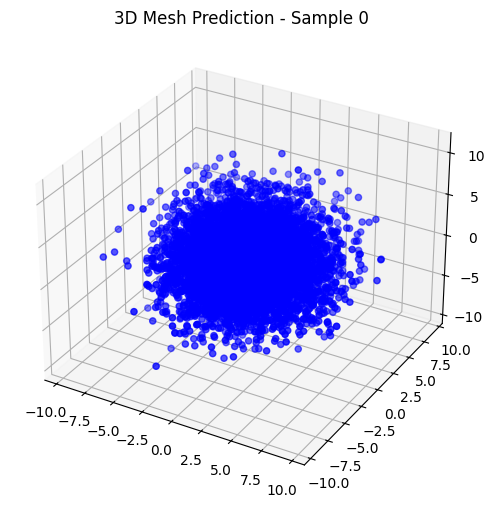

In [125]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def visualize_mesh(predicted_mesh, sample_idx=0):
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111, projection='3d')

    verts = predicted_mesh[sample_idx].reshape(-1, 3)
    verts *= 1000  # Scale for better visualization

    ax.scatter(verts[:, 0], verts[:, 2], -verts[:, 1], c='blue', marker='o')
    
    ax.set_title(f"3D Mesh Prediction - Sample {sample_idx}")
    plt.show()

# Example Visualization
visualize_mesh(predictions)



In [126]:
path = '/x1/ljiao/Bhanu/VIBE/Project/output/dance/Foolish_is_wood_46_girl_s_rule_girl_sitting_rules_dance_1_clip1.pkl'
